# Actividad 6. WODPredict-AI: evaluación y validación del modelo de sobrecarga

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/rick-lastra/Actividad_6/blob/main/evaluacion.ipynb)

**Objetivo:** evaluar y validar con métricas y pruebas el modelo de la Actividad 5 que predice si un atleta de
CrossFit tendrá **sobrecarga al día siguiente** (`overreaching_label = 1`), para UnderCover Fitness.


| Punto | Contenido |
|---|---|
| 0 | Preparación del entorno (versiones fijas) |
| 1 | Definición del problema, contexto y objetivo SMART |
| 2 | Código del modelo |
| 3 | Matriz de confusión e interpretación |
| 4 | Cálculo e interpretación de métricas |
| 5 | Ajuste de umbral |
| 6 | Curva ROC y AUC |
| 7 | Validación cruzada |
| 8 | Comparación con baseline y significancia estadística |
| 9 | Prueba A/B |
| 10 | Evidencia de experimentos (MLflow) |
| 11 | Tablero visual de resultados |
| 12 | Justificación técnica e impacto en el negocio |
| 13 | Conclusiones |

## 0. Preparación del entorno

Las versiones de las librerías quedan **fijas** en
`requirements.txt` y se imprimen al inicio para que cualquier persona obtenga los mismos resultados.

In [ ]:
# Punto 0. Preparación del entorno: librerías, versiones, semilla y MLflow.
import sys
import subprocess
import warnings
from pathlib import Path

# En Google Colab solo falta MLflow; se instala con la misma versión de requirements.txt.
if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "mlflow==3.4.0"])

warnings.filterwarnings("ignore")              # ocultar avisos que no cambian el resultado

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
import xgboost
import scipy
import statsmodels
import mlflow

SEMILLA = 42                                   # misma semilla = mismos resultados
RESULTADOS = Path("resultados")                # aquí se guardan gráficas y tablas para el tablero
RESULTADOS.mkdir(exist_ok=True)

# MLflow guarda los experimentos en el archivo mlflow.db  
import io
import logging
from contextlib import redirect_stderr
logging.getLogger("mlflow").setLevel(logging.ERROR)
with redirect_stderr(io.StringIO()):            
    mlflow.set_tracking_uri("sqlite:///mlflow.db")
    mlflow.set_experiment("actividad6-evaluacion")

# Versiones usadas (deben coincidir con requirements.txt).
versiones = {"python": sys.version.split()[0], "numpy": np.__version__, "pandas": pd.__version__,
             "scikit-learn": sklearn.__version__, "xgboost": xgboost.__version__, "scipy": scipy.__version__,
             "statsmodels": statsmodels.__version__, "matplotlib": matplotlib.__version__, "mlflow": mlflow.__version__}
for libreria, version in versiones.items():
    print(f"{libreria:13} {version}")

# Colores fijos para que cada modelo se vea igual en todas las gráficas.
COLOR = {"Regresión logística": "#2a78d6", "Random Forest": "#eb6834", "XGBoost": "#1baf7a",
         "Regla ACWR > 1.5": "#8a8a8a", "Clase mayoritaria": "#c9c9c9"}

python        3.12.15
numpy         2.0.2
pandas        2.2.2
scikit-learn  1.6.1
xgboost       3.0.5
scipy         1.16.3
statsmodels   0.14.5
matplotlib    3.10.0
mlflow        3.4.0


## 1. Definición del problema y contexto

**Contexto.** UnderCover Fitness quiere reducir 25 % la deserción de atletas causada por lesiones por acumulación de
fatiga. Es un problema de **salud deportiva** (cercano al contexto clínico): el modelo da una alerta al coach
*antes* de la sesión para que ajuste la carga.

**Problema de clasificación binaria.** Con información conocida antes de entrenar (carga y frecuencia de los últimos
días, ACWR, RPE de la sesión anterior y probabilidad de fatiga de sus comentarios) se predice si el atleta tendrá
sobrecarga al día siguiente (1) o no (0).

**Costo de los errores.** Un falso negativo (no avisar a un atleta que sí se sobrecarga) puede terminar en lesión y
baja del box. Un falso positivo solo cuesta una revisión del coach y, como mucho, una sesión más ligera. Por eso la
métrica principal es el **recall** y la precisión funciona como límite de alertas.

**Objetivo SMART de evaluación.**

| | |
|---|---|
| **Específico** | Detectar las sesiones con riesgo de sobrecarga al día siguiente en atletas que el modelo nunca vio |
| **Medible** | Recall ≥ 0.70, precisión ≥ 0.35 y ROC-AUC ≥ 0.80 en el conjunto de prueba; desviación del ROC-AUC < 0.03 en la validación cruzada |
| **Alcanzable** | El modelo ya tiene ROC-AUC 0.859; falta mover el umbral (hoy recall 0.27) |
| **Relevante** | Cada sobrecarga detectada es una lesión que se puede prevenir y un atleta que no deserta |
| **Temporal** | Validado antes del piloto con datos reales de Wodify |

**Datos y cómo se generó el dataset sintético** Se usa la versión limpia de la
Actividad 5 (`sesiones_limpias.csv`, tag `v1.0` del repositorio `rick-lastra/Actividad_5`), que viene del dataset
público [`rick-lastra/wodpredict-synth`](https://huggingface.co/datasets/rick-lastra/wodpredict-synth) (`v1.0`).

| Paso | Qué hace el generador (`wodpredict.synth`, semilla 42, parámetros en `configs/synth.yaml`) |
|---|---|
| 1. Atletas | 280 atletas (94 novato, 93 intermedio, 93 élite) con edad, sexo, idioma, capacidad y frecuencia semanal por nivel; 25 % entra tarde y 20 % asiste de forma irregular, como el atleta real |
| 2. Programación | Un WOD diario común al box (oct-2024 a sep-2026, domingo de descanso). La dificultad de cada WOD sale de las marcas reales del atleta de SugarWOD |
| 3. Fatiga oculta | Carga que decae con el tiempo + estrés/sueño oculto con choques (enfermedad, viajes). Nunca se entrega al modelo |
| 4. Resultados | Resultado = dificultad × capacidad × fatiga × ruido; RPE según fatiga y estrés; carga Foster = RPE × minutos |
| 5. Etiqueta | Sobrecarga = la fatiga del atleta supera su umbral individual; prevalencia calibrada a 15 % y 5 % de ruido de etiqueta (acuerdo del coach en la Actividad 4 = 97.6 %) |
| 6. Comentarios | Notas del banco de 84 comentarios etiquetados por el coach, con `prob_fatiga` del modelo XLM-R de la Actividad 4 |
| 7. Variables previas | ACWR, cargas y frecuencias calculadas solo con datos hasta el día anterior (sin fuga) |
| 8. Errores de captura | Para practicar la limpieza se agregaron duplicados, recapturas y errores en `level`; la Actividad 5 los limpió (87,258 → 81,901 sesiones) |

Validación del generador: la mediana de For Time sintética (783 s) es igual a la real (780 s; KS p = 0.97). El techo
teórico del ROC-AUC es cercano a 0.91 porque el estrés oculto no se observa.

In [2]:
# Punto 1. Carga de datos y descripción del problema.

# 1) Datos limpios de la Actividad 5, fijados en el tag v1.0 (reproducible: siempre es el mismo archivo).
URL_DATOS = "https://raw.githubusercontent.com/rick-lastra/Actividad_5/v1.0/datos/datos_limp/sesiones_limpias.csv"
datos = pd.read_csv(URL_DATOS)
DATASET = "rick-lastra/wodpredict-synth@v1.0 (limpio: Actividad_5@v1.0)"

# 2) Variables de entrada: todas se conocen ANTES de la sesión (las mismas de la Actividad 5).
NUMERICAS = ["age", "days_since_prev_session", "sessions_last_3d", "sessions_last_7d", "sessions_last_28d",
             "load_last_3d", "load_last_7d", "mean_session_load_28d",
             "acwr3_freq", "acwr3_load", "acwr_freq", "acwr_load",
             "days_since_first_session", "prev_rpe", "prev_session_load", "prev_has_note",
             "prob_fatiga_prev_session", "prob_fatiga_last_note", "days_since_last_note", "notes_last_28d"]
CATEGORICAS = ["level", "sex", "language"]
ETIQUETA = "overreaching_label"

# 3) Tamaño y desbalance de clases.
print(f"Sesiones: {len(datos):,} | atletas: {datos['athlete_id'].nunique()} | variables: {len(NUMERICAS + CATEGORICAS)}")
print(f"Sesiones con sobrecarga al día siguiente: {datos[ETIQUETA].mean():.1%}")
print(datos.groupby("level")[ETIQUETA].agg(sesiones="count", porcentaje_sobrecarga="mean").round(3))

# 4) Metas del objetivo SMART.
META_RECALL, META_PRECISION, META_AUC, META_DESV_AUC = 0.70, 0.35, 0.80, 0.03
print(f"\nMetas: recall ≥ {META_RECALL}, precisión ≥ {META_PRECISION}, ROC-AUC ≥ {META_AUC}, desviación ROC-AUC < {META_DESV_AUC}")

Sesiones: 81,901 | atletas: 280 | variables: 23
Sesiones con sobrecarga al día siguiente: 12.5%
            sesiones  porcentaje_sobrecarga
level                                      
intermedio     26672                  0.131
novato         21145                  0.181
élite          34084                  0.086

Metas: recall ≥ 0.7, precisión ≥ 0.35, ROC-AUC ≥ 0.8, desviación ROC-AUC < 0.03


## 2. Código del modelo

- **Separación 80/20 por atleta** (`GroupShuffleSplit`, semilla 42): el
  conjunto de prueba son 56 atletas que el modelo nunca vio.
- **Modelo seleccionado:** regresión logística (`C = 0.1`). También se reentrenan Random Forest y
  XGBoost con sus mejores hiperparámetros del Grid Search para compararlos.
- **Baselines:** (1) *clase mayoritaria*: siempre dice "sin sobrecarga"; (2) *regla ACWR > 1.5*: el criterio clásico
  que usa hoy el coach (alerta si la carga de 7 días supera 1.5 veces el promedio de 28 días).

In [3]:
# Punto 2. Separación por atleta, preprocesamiento, modelos y baselines.
from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from xgboost import XGBClassifier

# 1) X (entradas), y (etiqueta) y el atleta de cada sesión.
X = datos[NUMERICAS + CATEGORICAS]
y = datos[ETIQUETA]
atleta = datos["athlete_id"]

# 2) Separación 80/20 por atleta: un atleta está en entrenamiento o en prueba, nunca en los dos.
separador = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEMILLA)
idx_train, idx_test = next(separador.split(X, y, groups=atleta))
X_train, X_test = X.iloc[idx_train], X.iloc[idx_test]
y_train, y_test = y.iloc[idx_train], y.iloc[idx_test]
atleta_train, atleta_test = atleta.iloc[idx_train], atleta.iloc[idx_test]
print(f"Entrenamiento: {len(X_train):,} sesiones de {atleta_train.nunique()} atletas")
print(f"Prueba:        {len(X_test):,} sesiones de {atleta_test.nunique()} atletas")

# 3) Preprocesamiento dentro del Pipeline (se ajusta solo con los datos de entrenamiento).
def preprocesador(escalar):
    pasos = [("imputar", SimpleImputer(strategy="median"))]
    if escalar:
        pasos.append(("escalar", StandardScaler()))
    return ColumnTransformer([("num", Pipeline(pasos), NUMERICAS),
                              ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAS)])

# 4) Modelos con los mejores hiperparámetros encontrados en la Actividad 5.
modelos = {
    "Regresión logística": Pipeline([("prep", preprocesador(True)),
                                     ("modelo", LogisticRegression(C=0.1, max_iter=3000, random_state=SEMILLA))]),
    "Random Forest": Pipeline([("prep", preprocesador(False)),
                               ("modelo", RandomForestClassifier(n_estimators=200, max_depth=16, min_samples_leaf=25,
                                                                 max_features="sqrt", class_weight="balanced_subsample",
                                                                 n_jobs=-1, random_state=SEMILLA))]),
    "XGBoost": Pipeline([("prep", preprocesador(False)),
                         ("modelo", XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8,
                                                  colsample_bytree=0.8, eval_metric="logloss", n_jobs=-1,
                                                  random_state=SEMILLA))]),
    "Clase mayoritaria": DummyClassifier(strategy="most_frequent"),
}

# 5) Regla del coach: "probabilidad" = ACWR por carga; alerta si es mayor a 1.5.
def regla_acwr(X_datos):
    return X_datos["acwr_load"].fillna(0).to_numpy()
UMBRAL_REGLA = 1.5

# 6) Entrenar y guardar la probabilidad de sobrecarga de cada sesión de prueba.
prob_test = {}
for nombre, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    prob_test[nombre] = modelo.predict_proba(X_test)[:, 1]
    print(f"{nombre}: entrenado")
prob_test["Regla ACWR > 1.5"] = regla_acwr(X_test)

Entrenamiento: 65,403 sesiones de 224 atletas
Prueba:        16,498 sesiones de 56 atletas
Regresión logística: entrenado
Random Forest: entrenado
XGBoost: entrenado
Clase mayoritaria: entrenado


## 3. Matriz de confusión e interpretación

La matriz compara lo real (filas) contra lo que predice el modelo (columnas) con el umbral de 0.5:

| | Predice 0 (sin alerta) | Predice 1 (alerta) |
|---|---|---|
| **Real 0** | VN: sin sobrecarga y sin alerta | FP: falsa alarma, el coach revisa de más |
| **Real 1** | **FN: sobrecarga no detectada (el error caro)** | VP: sobrecarga detectada a tiempo |

Se pone junto al baseline de clase mayoritaria para mostrar por qué la exactitud engaña con clases desbalanceadas.

Regresión logística: VN=14,131  FP=293  FN=1,525  VP=549
Clase mayoritaria: VN=14,424  FP=0  FN=2,074  VP=0


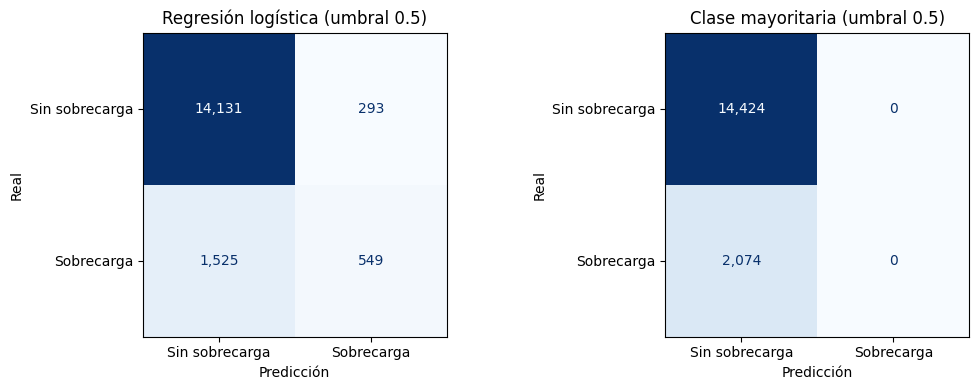


De 2,074 sesiones con sobrecarga real, el modelo detecta 549 y deja pasar 1,525 (74%).
De 842 alertas, 549 son correctas (65%): las alertas son confiables, pero se escapan la mayoría de los casos.


In [4]:
# Punto 3. Matriz de confusión del modelo seleccionado (umbral 0.5) frente a la clase mayoritaria.
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
for eje, nombre in zip(ejes, ["Regresión logística", "Clase mayoritaria"]):
    prediccion = (prob_test[nombre] >= 0.5).astype(int)
    matriz = confusion_matrix(y_test, prediccion, labels=[0, 1])
    ConfusionMatrixDisplay(matriz, display_labels=["Sin sobrecarga", "Sobrecarga"]).plot(ax=eje, cmap="Blues", colorbar=False, values_format=",")
    eje.set(title=f"{nombre} (umbral 0.5)", xlabel="Predicción", ylabel="Real")
    vn, fp, fn, vp = matriz.ravel()
    print(f"{nombre}: VN={vn:,}  FP={fp:,}  FN={fn:,}  VP={vp:,}")
plt.tight_layout()
plt.savefig(RESULTADOS / "matriz_confusion_05.png", dpi=150)
plt.show()

# Interpretación con los números del modelo seleccionado.
vn, fp, fn, vp = confusion_matrix(y_test, (prob_test["Regresión logística"] >= 0.5).astype(int)).ravel()
print(f"\nDe {vp + fn:,} sesiones con sobrecarga real, el modelo detecta {vp:,} y deja pasar {fn:,} ({fn / (vp + fn):.0%}).")
print(f"De {vp + fp:,} alertas, {vp:,} son correctas ({vp / (vp + fp):.0%}): las alertas son confiables, pero se escapan la mayoría de los casos.")

## 4. Cálculo e interpretación de métricas

| Métrica | Fórmula | Qué responde en WODPredict-AI |
|---|---|---|
| Exactitud | (VP + VN) / total | ¿Qué % de sesiones clasifica bien? Engañosa: decir siempre "no" da 87 % |
| Precisión | VP / (VP + FP) | De las alertas al coach, ¿cuántas eran sobrecarga real? (carga de trabajo del coach) |
| Recall | VP / (VP + FN) | De las sobrecargas reales, ¿cuántas detectamos? (**métrica principal**) |
| F1-score | 2·P·R / (P + R) | Balance entre precisión y recall |
| ROC-AUC | área bajo la curva ROC | ¿Qué tan bien ordena el riesgo, sin importar el umbral? |

In [5]:
# Punto 4. Métricas de todos los modelos y baselines en prueba con el umbral por defecto.
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

def metricas(y_real, probabilidad, umbral):
    """Exactitud, precisión, recall, F1 y ROC-AUC para un umbral dado."""
    prediccion = (probabilidad >= umbral).astype(int)
    return {"Exactitud": accuracy_score(y_real, prediccion),
            "Precisión": precision_score(y_real, prediccion, zero_division=0),
            "Recall": recall_score(y_real, prediccion),
            "F1": f1_score(y_real, prediccion),
            "ROC-AUC": roc_auc_score(y_real, probabilidad),
            "% alertas": prediccion.mean()}

UMBRAL_DEFECTO = {"Regresión logística": 0.5, "Random Forest": 0.5, "XGBoost": 0.5,
                  "Clase mayoritaria": 0.5, "Regla ACWR > 1.5": UMBRAL_REGLA}
tabla_05 = pd.DataFrame({nombre: metricas(y_test, prob_test[nombre], UMBRAL_DEFECTO[nombre])
                         for nombre in prob_test}).T.round(3)
tabla_05.to_csv(RESULTADOS / "metricas_umbral_defecto.csv")
display(tabla_05)
print("La clase mayoritaria tiene la mejor exactitud y no detecta a nadie: por eso se evalúa con recall, F1 y ROC-AUC.")

,Exactitud,Precisión,Recall,F1,ROC-AUC,% alertas
Regresión logística,0.890,0.652,0.265,0.377,0.859,0.051
Random Forest,0.819,0.383,0.719,0.500,0.854,0.236
XGBoost,0.889,0.621,0.298,0.403,0.855,0.060
Clase mayoritaria,0.874,0.000,0.000,0.000,0.500,0.000
Regla ACWR > 1.5,0.830,0.313,0.297,0.305,0.741,0.120


La clase mayoritaria tiene la mejor exactitud y no detecta a nadie: por eso se evalúa con recall, F1 y ROC-AUC.


## 5. Ajuste de umbral

Con 0.5 el modelo casi no da alertas. El umbral se elige **solo con datos de entrenamiento**, usando predicciones
*fuera del fold* (validación cruzada de 5 folds por atleta), y después se reporta en prueba. Así el conjunto de
prueba no influye en la decisión.

**Regla de decisión:** el umbral más alto que logra **recall ≥ 0.70** (la meta SMART). Es el punto con menos falsas
alarmas que todavía cumple la meta de detección. Se hace lo mismo para los tres modelos para compararlos en igualdad.

Regresión logística: umbral elegido = 0.17 (F1 máximo en 0.22)
Random Forest: umbral elegido = 0.50 (F1 máximo en 0.60)
XGBoost: umbral elegido = 0.17 (F1 máximo en 0.26)


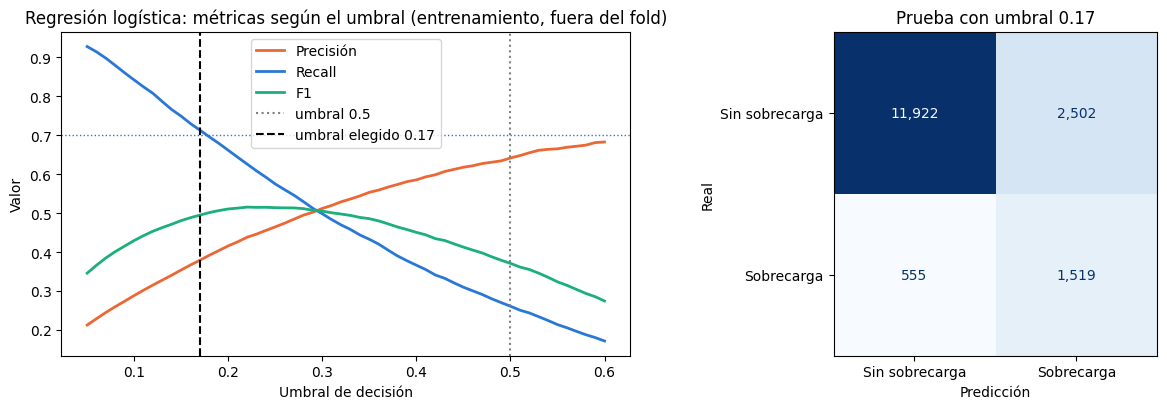

,Exactitud,Precisión,Recall,F1,ROC-AUC,% alertas
Umbral 0.5,0.890,0.652,0.265,0.377,0.859,0.051
Umbral 0.17,0.815,0.378,0.732,0.498,0.859,0.244


,Recall umbral 0.5,Recall umbral elegido,Precisión umbral elegido
intermedio,0.258,0.735,0.372
novato,0.338,0.799,0.448
élite,0.154,0.623,0.290


In [6]:
# Punto 5. Ajuste del umbral con predicciones fuera del fold (solo entrenamiento) y efecto en prueba.
from sklearn.model_selection import GroupKFold, cross_val_predict

umbrales = np.round(np.arange(0.05, 0.61, 0.01), 2)
UMBRAL = {"Clase mayoritaria": 0.5, "Regla ACWR > 1.5": UMBRAL_REGLA}
curvas = {}
for nombre in ["Regresión logística", "Random Forest", "XGBoost"]:
    # 1) Probabilidad de cada sesión de entrenamiento predicha por un modelo que no la vio.
    prob_oof = cross_val_predict(modelos[nombre], X_train, y_train, groups=atleta_train,
                                 cv=GroupKFold(n_splits=5), method="predict_proba")[:, 1]
    # 2) Precisión, recall y F1 para cada umbral candidato.
    curva = pd.DataFrame([metricas(y_train, prob_oof, u) for u in umbrales], index=umbrales)
    curvas[nombre] = curva
    # 3) Umbral más alto que cumple recall >= 0.70.
    UMBRAL[nombre] = curva[curva["Recall"] >= META_RECALL].index.max()
    print(f"{nombre}: umbral elegido = {UMBRAL[nombre]:.2f} (F1 máximo en {curva['F1'].idxmax():.2f})")

# 4) Gráfica de precisión, recall y F1 según el umbral (modelo seleccionado).
curva = curvas["Regresión logística"]
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.2))
for columna, color in [("Precisión", "#eb6834"), ("Recall", "#2a78d6"), ("F1", "#1baf7a")]:
    ejes[0].plot(curva.index, curva[columna], label=columna, color=color, lw=2)
ejes[0].axvline(0.5, color="gray", ls=":", label="umbral 0.5")
ejes[0].axvline(UMBRAL["Regresión logística"], color="black", ls="--", label=f"umbral elegido {UMBRAL['Regresión logística']:.2f}")
ejes[0].axhline(META_RECALL, color="#2a78d6", ls=":", lw=1)
ejes[0].set(xlabel="Umbral de decisión", ylabel="Valor", title="Regresión logística: métricas según el umbral (entrenamiento, fuera del fold)")
ejes[0].legend()

# 5) Matriz de confusión en prueba con el umbral elegido.
prediccion = (prob_test["Regresión logística"] >= UMBRAL["Regresión logística"]).astype(int)
matriz = confusion_matrix(y_test, prediccion)
ConfusionMatrixDisplay(matriz, display_labels=["Sin sobrecarga", "Sobrecarga"]).plot(ax=ejes[1], cmap="Blues", colorbar=False, values_format=",")
ejes[1].set(title=f"Prueba con umbral {UMBRAL['Regresión logística']:.2f}", xlabel="Predicción", ylabel="Real")
plt.tight_layout()
plt.savefig(RESULTADOS / "ajuste_umbral.png", dpi=150)
plt.show()

# 6) Antes y después en prueba.
antes_despues = pd.DataFrame({"Umbral 0.5": metricas(y_test, prob_test["Regresión logística"], 0.5),
                              f"Umbral {UMBRAL['Regresión logística']:.2f}": metricas(y_test, prob_test["Regresión logística"], UMBRAL["Regresión logística"])}).T.round(3)
display(antes_despues)

# 7) Recall por nivel (en la Actividad 5 los atletas élite tenían recall 0.15).
prueba = X_test.assign(real=y_test.values, prob=prob_test["Regresión logística"])
por_nivel = pd.DataFrame({nivel: {"Recall umbral 0.5": recall_score(g["real"], g["prob"] >= 0.5),
                                  "Recall umbral elegido": recall_score(g["real"], g["prob"] >= UMBRAL["Regresión logística"]),
                                  "Precisión umbral elegido": precision_score(g["real"], g["prob"] >= UMBRAL["Regresión logística"])}
                          for nivel, g in prueba.groupby("level")}).T.round(3)
display(por_nivel)

## 6. Curva ROC y AUC

La curva ROC muestra, para **todos** los umbrales posibles, la tasa de verdaderos positivos (recall) contra la tasa de
falsos positivos (falsas alarmas entre los atletas sanos). El **AUC** es la probabilidad de que el modelo le dé más
riesgo a una sesión con sobrecarga que a una sin sobrecarga: 0.5 = azar, 1 = perfecto. Mover el umbral solo cambia el
punto de operación sobre la curva; el AUC no cambia.


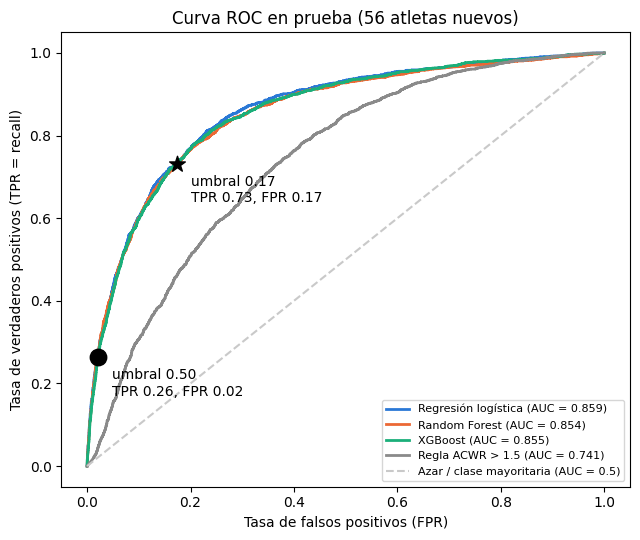

ROC-AUC regresión logística = 0.859 (IC 95 %: 0.846 a 0.871) -> meta ≥ 0.8: cumple


In [7]:
# Punto 6. Curvas ROC en prueba, puntos de operación e intervalo de confianza del AUC.
from sklearn.metrics import roc_curve

fig, eje = plt.subplots(figsize=(6.5, 5.5))
for nombre in ["Regresión logística", "Random Forest", "XGBoost", "Regla ACWR > 1.5"]:
    fpr, tpr, _ = roc_curve(y_test, prob_test[nombre])
    eje.plot(fpr, tpr, color=COLOR[nombre], lw=2, label=f"{nombre} (AUC = {roc_auc_score(y_test, prob_test[nombre]):.3f})")
eje.plot([0, 1], [0, 1], color="#c9c9c9", ls="--", label="Azar / clase mayoritaria (AUC = 0.5)")

# Puntos de operación del modelo seleccionado: umbral 0.5 y umbral elegido.
for umbral, marca in [(0.5, "o"), (UMBRAL["Regresión logística"], "*")]:
    pred = prob_test["Regresión logística"] >= umbral
    tpr_punto = pred[y_test == 1].mean()
    fpr_punto = pred[y_test == 0].mean()
    eje.scatter(fpr_punto, tpr_punto, s=140, marker=marca, color="black", zorder=3)
    eje.annotate(f"umbral {umbral:.2f}\nTPR {tpr_punto:.2f}, FPR {fpr_punto:.2f}", (fpr_punto, tpr_punto),
                 xytext=(10, -28), textcoords="offset points")
eje.set(xlabel="Tasa de falsos positivos (FPR)", ylabel="Tasa de verdaderos positivos (TPR = recall)", title="Curva ROC en prueba (56 atletas nuevos)")
eje.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.savefig(RESULTADOS / "curva_roc.png", dpi=150)
plt.show()

# Intervalo de confianza del 95 % del AUC con 500 remuestreos de atletas.
rng = np.random.default_rng(SEMILLA)
atletas_prueba = atleta_test.unique()
posiciones = {a: np.flatnonzero(atleta_test.values == a) for a in atletas_prueba}
auc_boot = []
for _ in range(500):
    muestra = rng.choice(atletas_prueba, size=len(atletas_prueba), replace=True)
    filas = np.concatenate([posiciones[a] for a in muestra])
    auc_boot.append(roc_auc_score(y_test.values[filas], prob_test["Regresión logística"][filas]))
IC_AUC = np.percentile(auc_boot, [2.5, 97.5])
print(f"ROC-AUC regresión logística = {roc_auc_score(y_test, prob_test['Regresión logística']):.3f} "
      f"(IC 95 %: {IC_AUC[0]:.3f} a {IC_AUC[1]:.3f}) -> meta ≥ {META_AUC}: {'cumple' if IC_AUC[0] >= META_AUC else 'no cumple'}")

## 7. Validación cruzada

**Validación cruzada de 10 folds agrupada por atleta** (`GroupKFold`) sobre el 80 % de entrenamiento: en cada vuelta se
entrena con 9 folds y se evalúa con el fold restante, cuyos atletas no se usaron para entrenar. Se reporta el
promedio y la desviación estándar. Una desviación pequeña indica que el modelo **generaliza** a atletas nuevos y no
depende de qué atletas cayeron en cada grupo. Cada modelo se evalúa con su umbral elegido en el punto 5.

Exactitud        Precisión        Recall            F1  \
                         mean    std      mean    std   mean    std   mean   
modelo                                                                       
Regresión logística     0.821  0.013     0.384  0.039  0.710  0.034  0.497   
Random Forest           0.821  0.012     0.383  0.037  0.705  0.028  0.495   
XGBoost                 0.821  0.017     0.385  0.045  0.712  0.033  0.498   
Regla ACWR > 1.5        0.826  0.012     0.289  0.033  0.269  0.016  0.278   
Clase mayoritaria       0.875  0.016     0.000  0.000  0.000  0.000  0.000   

                           ROC-AUC         
                       std    mean    std  
modelo                                     
Regresión logística  0.032   0.853  0.005  
Random Forest        0.030   0.852  0.006  
XGBoost              0.036   0.852  0.005  
Regla ACWR > 1.5     0.016   0.728  0.012  
Clase mayoritaria    0.000   0.500  0.000

Desviación del ROC-AUC (regresión logística): 0.005 -> meta < 0.03: cumple


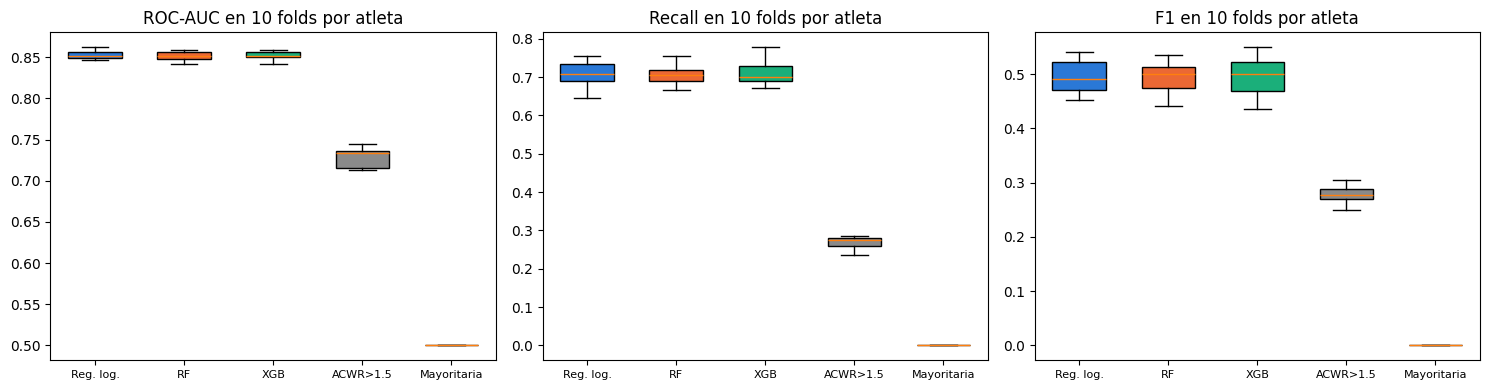

In [8]:
# Punto 7. Validación cruzada de 10 folds por atleta (mismos folds para todos los modelos).
validacion = GroupKFold(n_splits=10)
filas = []
for fold, (i_ent, i_val) in enumerate(validacion.split(X_train, y_train, groups=atleta_train), start=1):
    X_ent, X_val = X_train.iloc[i_ent], X_train.iloc[i_val]
    y_ent, y_val = y_train.iloc[i_ent], y_train.iloc[i_val]
    for nombre in ["Regresión logística", "Random Forest", "XGBoost", "Clase mayoritaria", "Regla ACWR > 1.5"]:
        if nombre == "Regla ACWR > 1.5":
            probabilidad = regla_acwr(X_val)                      # la regla no se entrena
        else:
            probabilidad = modelos[nombre].fit(X_ent, y_ent).predict_proba(X_val)[:, 1]
        filas.append({"fold": fold, "modelo": nombre, **metricas(y_val, probabilidad, UMBRAL[nombre])})
cv = pd.DataFrame(filas)
cv.to_csv(RESULTADOS / "validacion_cruzada_folds.csv", index=False)

# Promedio ± desviación estándar por modelo.
resumen_cv = cv.groupby("modelo")[["Exactitud", "Precisión", "Recall", "F1", "ROC-AUC"]].agg(["mean", "std"]).round(3)
resumen_cv = resumen_cv.loc[["Regresión logística", "Random Forest", "XGBoost", "Regla ACWR > 1.5", "Clase mayoritaria"]]
display(resumen_cv)
desv_auc = cv[cv["modelo"] == "Regresión logística"]["ROC-AUC"].std()
print(f"Desviación del ROC-AUC (regresión logística): {desv_auc:.3f} -> meta < {META_DESV_AUC}: {'cumple' if desv_auc < META_DESV_AUC else 'no cumple'}")

# Distribución por fold.
orden = ["Regresión logística", "Random Forest", "XGBoost", "Regla ACWR > 1.5", "Clase mayoritaria"]
fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
for eje, metrica in zip(ejes, ["ROC-AUC", "Recall", "F1"]):
    valores = [cv[cv["modelo"] == m][metrica] for m in orden]
    caja = eje.boxplot(valores, patch_artist=True, widths=0.6)
    for parche, m in zip(caja["boxes"], orden):
        parche.set_facecolor(COLOR[m])
    eje.set_xticks(range(1, 6), ["Reg. log.", "RF", "XGB", "ACWR>1.5", "Mayoritaria"], fontsize=8)
    eje.set_title(f"{metrica} en 10 folds por atleta")
plt.tight_layout()
plt.savefig(RESULTADOS / "validacion_cruzada.png", dpi=150)
plt.show()

## 8. Comparación con baseline y significancia estadística

¿La mejora sobre los baselines es real o casualidad? Se comparan los modelos **fold por fold** (los 10 folds del punto
7 son los mismos para todos) con dos pruebas pareadas:

- **t de Student pareada** (supone diferencias con distribución normal).
- **Wilcoxon de rangos con signo** (no supone normalidad).

Como se hacen varias comparaciones se usa la corrección de **Bonferroni**: α = 0.05 / número de comparaciones.
Además, en el conjunto de prueba se aplica la **prueba de McNemar**, que compara los errores de dos clasificadores
sobre las mismas sesiones.

In [9]:
# Punto 8. Comparación contra los baselines y entre modelos, con pruebas de significancia.
from scipy import stats
from statsmodels.stats.contingency_tables import mcnemar

comparaciones = [("Regresión logística", "Clase mayoritaria"), ("Regresión logística", "Regla ACWR > 1.5"),
                 ("Regresión logística", "Random Forest"), ("Regresión logística", "XGBoost")]
ALFA = 0.05 / len(comparaciones)                       # Bonferroni
filas = []
for a, b in comparaciones:
    for metrica in ["ROC-AUC", "F1", "Recall"]:
        valores_a = cv[cv["modelo"] == a][metrica].to_numpy()
        valores_b = cv[cv["modelo"] == b][metrica].to_numpy()
        diferencia = valores_a - valores_b
        p_t = stats.ttest_rel(valores_a, valores_b).pvalue
        p_w = stats.wilcoxon(valores_a, valores_b).pvalue if np.any(diferencia != 0) else 1.0
        filas.append({"Comparación": f"{a} vs {b}", "Métrica": metrica, "Diferencia media": diferencia.mean(),
                      "p t pareada": p_t, "p Wilcoxon": p_w, "¿Significativa?": "Sí" if max(p_t, p_w) < ALFA else "No"})
significancia = pd.DataFrame(filas).round(4)
significancia.to_csv(RESULTADOS / "significancia.csv", index=False)
print(f"Nivel de significancia con Bonferroni: α = 0.05 / {len(comparaciones)} = {ALFA:.4f}")
display(significancia)

# McNemar en prueba: regresión logística (umbral elegido) vs regla ACWR > 1.5.
acierto_modelo = (prob_test["Regresión logística"] >= UMBRAL["Regresión logística"]).astype(int) == y_test.values
acierto_regla = (prob_test["Regla ACWR > 1.5"] >= UMBRAL_REGLA).astype(int) == y_test.values
tabla_mcnemar = [[np.sum(acierto_modelo & acierto_regla), np.sum(acierto_modelo & ~acierto_regla)],
                 [np.sum(~acierto_modelo & acierto_regla), np.sum(~acierto_modelo & ~acierto_regla)]]
P_MCNEMAR = mcnemar(tabla_mcnemar, exact=False, correction=True).pvalue
print(f"McNemar (prueba): solo acierta el modelo = {tabla_mcnemar[0][1]:,}, solo acierta la regla = {tabla_mcnemar[1][0]:,}, p = {P_MCNEMAR:.2e}")

Nivel de significancia con Bonferroni: α = 0.05 / 4 = 0.0125


,Comparación,Métrica,Diferencia media,p t pareada,p Wilcoxon,¿Significativa?
0,Regresión logística vs Clase mayoritaria,ROC-AUC,0.3528,0.0000,0.0020,Sí
1,Regresión logística vs Clase mayoritaria,F1,0.4966,0.0000,0.0020,Sí
2,Regresión logística vs Clase mayoritaria,Recall,0.7098,0.0000,0.0020,Sí
3,Regresión logística vs Regla ACWR > 1.5,ROC-AUC,0.1248,0.0000,0.0020,Sí
4,Regresión logística vs Regla ACWR > 1.5,F1,0.2187,0.0000,0.0020,Sí
5,Regresión logística vs Regla ACWR > 1.5,Recall,0.4407,0.0000,0.0020,Sí
6,Regresión logística vs Random Forest,ROC-AUC,0.0013,0.2869,0.3750,No
7,Regresión logística vs Random Forest,F1,0.0016,0.5246,0.6250,No
8,Regresión logística vs Random Forest,Recall,0.0049,0.2833,0.2754,No
9,Regresión logística vs XGBoost,ROC-AUC,0.0012,0.4804,0.4922,No


McNemar (prueba): solo acierta el modelo = 1,668, solo acierta la regla = 1,913, p = 4.55e-05


## 9. Prueba A/B

La validación cruzada responde *"¿el modelo generaliza con datos históricos?"* (fase de desarrollo). La prueba A/B
responde *"¿la nueva versión funciona mejor con usuarios reales?"* (fase de producción).

| | Validación cruzada | Prueba A/B |
|---|---|---|
| Fase | Desarrollo | Producción (piloto) |
| Datos | Históricos, ya etiquetados | Nuevos, en tiempo real |
| Qué compara | Modelos o configuraciones | Versiones del sistema con usuarios reales |
| Unidad | Fold de atletas | Atleta asignado al azar a A o B |
| Métrica | ROC-AUC, F1, recall | Sobrecargas detectadas, alertas por coach, lesiones, deserción |

**Cómo se complementan.** La validación cruzada filtra en desarrollo (elige modelo y umbral); la prueba A/B decide en
producción (mide el efecto real en lesiones y deserción). Regla: implementar B solo si la validación cruzada muestra
que generaliza (desviación del ROC-AUC < 0.03) **y** el piloto A/B muestra una mejora significativa en la detección
sin pasar el límite de alertas que el coach puede revisar.

**Diseño (pasos del Tema 14).**
1. **Objetivo:** aumentar el % de sobrecargas que reciben una alerta a tiempo.
2. **Modelos:** A (control) = modelo actual de la Actividad 5 con umbral 0.5; B (experimental) = mismo modelo con el umbral ajustado.
3. **División:** los 56 atletas de prueba se asignan al azar, por atleta, 50 % a A y 50 % a B.
4. **Ejecución:** cada grupo recibe solo las alertas de su versión (aquí se simula con los datos de prueba).
5. **Métricas:** principal = tasa de detección (recall); de control = % de sesiones con alerta (carga del coach) y precisión.
6. **Análisis:** prueba z de dos proporciones (H0: la detección es igual en A y B) y una prueba de permutación por
   atleta, porque las sesiones de un mismo atleta no son independientes.
7. **Decisión:** se adopta B si la mejora es significativa (p < 0.05) y la carga de alertas es manejable.

,Versión,Atletas,Sesiones,Sobrecargas reales,Detectadas,Tasa de detección,% sesiones con alerta,Precisión
Grupo,,,,,,,,
A,umbral 0.50,28,8534,1088,331,0.304,0.058,0.667
B,umbral 0.17,28,7964,986,688,0.698,0.229,0.377


Mejora en detección (B - A): +0.394 | z = 17.90 | p = 5.55e-72
Permutación por atleta: B supera a A en 100.0% de 1,000 asignaciones (p = 0.000)
Piloto en Wodify: se necesitan ≈ 268 sobrecargas por grupo para detectar +10 puntos de recall


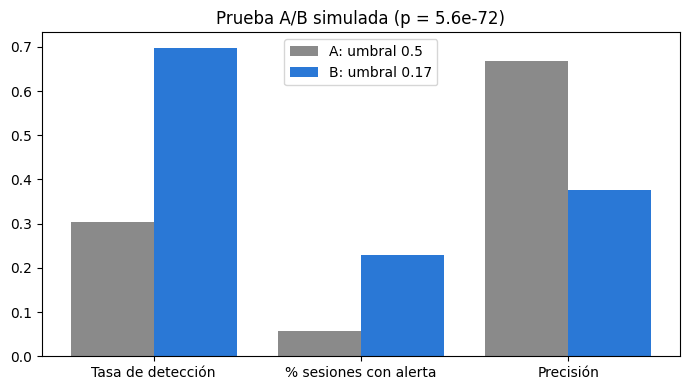

In [10]:
# Punto 9. Simulación de la prueba A/B con los atletas de prueba.
from statsmodels.stats.proportion import proportions_ztest, proportion_effectsize
from statsmodels.stats.power import NormalIndPower

# 1) Asignación aleatoria por atleta: 28 atletas al grupo A y 28 al grupo B.
rng = np.random.default_rng(SEMILLA)
atletas_b = rng.choice(atletas_prueba, size=len(atletas_prueba) // 2, replace=False)
ab = pd.DataFrame({"atleta": atleta_test.values, "real": y_test.values, "prob": prob_test["Regresión logística"]})
ab["grupo"] = np.where(ab["atleta"].isin(atletas_b), "B", "A")

# 2) Cada grupo recibe alertas con su versión: A = umbral 0.5, B = umbral ajustado.
UMBRAL_AB = {"A": 0.5, "B": UMBRAL["Regresión logística"]}
ab["alerta"] = (ab["prob"] >= ab["grupo"].map(UMBRAL_AB)).astype(int)

# 3) Métricas por grupo.
filas = []
for grupo, g in ab.groupby("grupo"):
    positivos = g[g["real"] == 1]
    filas.append({"Grupo": grupo, "Versión": f"umbral {UMBRAL_AB[grupo]:.2f}", "Atletas": g["atleta"].nunique(),
                  "Sesiones": len(g), "Sobrecargas reales": len(positivos), "Detectadas": positivos["alerta"].sum(),
                  "Tasa de detección": positivos["alerta"].mean(), "% sesiones con alerta": g["alerta"].mean(),
                  "Precisión": g.loc[g["alerta"] == 1, "real"].mean()})
resultado_ab = pd.DataFrame(filas).set_index("Grupo").round(3)
display(resultado_ab)

# 4) Prueba z de dos proporciones sobre la tasa de detección.
detectadas = resultado_ab["Detectadas"].to_numpy()
reales = resultado_ab["Sobrecargas reales"].to_numpy()
z, P_AB = proportions_ztest(detectadas[::-1], reales[::-1], alternative="larger")   # H1: B > A
diferencia = resultado_ab.loc["B", "Tasa de detección"] - resultado_ab.loc["A", "Tasa de detección"]
print(f"Mejora en detección (B - A): {diferencia:+.3f} | z = {z:.2f} | p = {P_AB:.2e}")

# 5) Prueba de permutación por atleta: se reasignan los grupos 1,000 veces al azar.
def mejora(asignacion_b):
    grupo_b = ab["atleta"].isin(asignacion_b)
    alerta = np.where(grupo_b, ab["prob"] >= UMBRAL_AB["B"], ab["prob"] >= UMBRAL_AB["A"])
    positivos = ab["real"] == 1
    return alerta[positivos & grupo_b].mean() - alerta[positivos & ~grupo_b].mean()
mejoras_azar = [mejora(rng.choice(atletas_prueba, size=len(atletas_b), replace=False)) for _ in range(1000)]
P_PERMUTACION = np.mean(np.array(mejoras_azar) <= 0)       # veces que B NO supera a A
print(f"Permutación por atleta: B supera a A en {1 - P_PERMUTACION:.1%} de 1,000 asignaciones (p = {P_PERMUTACION:.3f})")

# 6) Tamaño de muestra para un piloto real: detectar +10 puntos de recall con 80 % de potencia y α = 0.05.
efecto = proportion_effectsize(0.37, 0.27)
casos_por_grupo = NormalIndPower().solve_power(effect_size=efecto, power=0.8, alpha=0.05, alternative="larger")
print(f"Piloto en Wodify: se necesitan ≈ {casos_por_grupo:.0f} sobrecargas por grupo para detectar +10 puntos de recall")

# 7) Gráfica.
fig, eje = plt.subplots(figsize=(7, 4))
x = np.arange(3)
columnas = ["Tasa de detección", "% sesiones con alerta", "Precisión"]
eje.bar(x - 0.2, resultado_ab.loc["A", columnas], width=0.4, color="#8a8a8a", label=f"A: umbral 0.5")
eje.bar(x + 0.2, resultado_ab.loc["B", columnas], width=0.4, color="#2a78d6", label=f"B: umbral {UMBRAL_AB['B']:.2f}")
eje.set_xticks(x, columnas)
eje.set_title(f"Prueba A/B simulada (p = {P_AB:.1e})")
eje.legend()
plt.tight_layout()
plt.savefig(RESULTADOS / "prueba_ab.png", dpi=150)
plt.show()

## 10. Evidencia de experimentos (MLflow)

Cada modelo se registra como un *run* del experimento `actividad6-evaluacion` con:
- **Parámetros:** hiperparámetros, umbral, versión del dataset y versiones de las librerías.
- **Métricas:** prueba con umbral 0.5, prueba con umbral ajustado y validación cruzada (promedio y desviación).
- **Artefactos:** gráficas y tablas; el modelo seleccionado se guarda con su firma.
- Un run adicional guarda la comparación estadística y la prueba A/B.

Para ver el panel: `mlflow ui --backend-store-uri sqlite:///mlflow.db --port 5000` y abrir http://127.0.0.1:5000.

In [11]:
# Punto 10. Registro de los experimentos en MLflow y tabla de evidencia.
from mlflow.models import infer_signature

for nombre in ["Regresión logística", "Random Forest", "XGBoost", "Regla ACWR > 1.5", "Clase mayoritaria"]:
    with mlflow.start_run(run_name=nombre):
        mlflow.log_param("dataset", DATASET)
        mlflow.log_param("umbral", UMBRAL[nombre])
        mlflow.log_params({f"version_{k}": v for k, v in versiones.items()})
        if nombre in modelos and hasattr(modelos[nombre], "named_steps"):
            mlflow.log_params(modelos[nombre].named_steps["modelo"].get_params())
        for metrica, valor in metricas(y_test, prob_test[nombre], UMBRAL_DEFECTO[nombre]).items():
            mlflow.log_metric("test_defecto_" + metrica.replace("% ", "pct_").replace("-", "_"), valor)
        for metrica, valor in metricas(y_test, prob_test[nombre], UMBRAL[nombre]).items():
            mlflow.log_metric("test_umbral_" + metrica.replace("% ", "pct_").replace("-", "_"), valor)
        for metrica in ["Precisión", "Recall", "F1", "ROC-AUC"]:
            mlflow.log_metric("cv_media_" + metrica.replace("-", "_"), cv[cv["modelo"] == nombre][metrica].mean())
            mlflow.log_metric("cv_desv_" + metrica.replace("-", "_"), cv[cv["modelo"] == nombre][metrica].std())
        if nombre == "Regresión logística":                       # modelo seleccionado
            mlflow.set_tag("seleccionado", "sí")
            for archivo in RESULTADOS.glob("*.png"):
                mlflow.log_artifact(str(archivo), "graficas")
            firma = infer_signature(X_test, prob_test[nombre])
            mlflow.sklearn.log_model(modelos[nombre], name="modelo", signature=firma, input_example=X_test.head(3))

with mlflow.start_run(run_name="Comparación estadística y prueba A/B"):
    mlflow.log_params({"alfa_bonferroni": ALFA, "umbral_A": UMBRAL_AB["A"], "umbral_B": UMBRAL_AB["B"]})
    mlflow.log_metrics({"p_mcnemar_logistica_vs_regla": P_MCNEMAR, "ab_mejora_deteccion": diferencia,
                        "ab_p_ztest": P_AB, "ab_p_permutacion": P_PERMUTACION})
    mlflow.log_artifact(str(RESULTADOS / "significancia.csv"))
    mlflow.log_artifact(str(RESULTADOS / "validacion_cruzada_folds.csv"))

# Evidencia: lo que quedó registrado.
runs = mlflow.search_runs(experiment_names=["actividad6-evaluacion"])
columnas = ["tags.mlflow.runName", "params.umbral", "metrics.test_umbral_Recall", "metrics.test_umbral_Precisión",
            "metrics.test_umbral_F1", "metrics.test_umbral_ROC_AUC", "metrics.cv_media_ROC_AUC", "metrics.cv_desv_ROC_AUC"]
display(runs[columnas].dropna(subset=["params.umbral"]).round(3))
print(f"Runs registrados en 'actividad6-evaluacion': {len(runs)}")

,tags.mlflow.runName,params.umbral,metrics.test_umbral_Recall,metrics.test_umbral_Precisión,metrics.test_umbral_F1,metrics.test_umbral_ROC_AUC,metrics.cv_media_ROC_AUC,metrics.cv_desv_ROC_AUC
1,Clase mayoritaria,0.5,0.000,0.000,0.000,0.500,0.500,0.000
2,Regla ACWR > 1.5,1.5,0.297,0.313,0.305,0.741,0.728,0.012
3,XGBoost,0.17,0.722,0.388,0.504,0.855,0.852,0.005
4,Random Forest,0.5,0.719,0.383,0.500,0.854,0.852,0.006
5,Regresión logística,0.17,0.732,0.378,0.498,0.859,0.853,0.005


Runs registrados en 'actividad6-evaluacion': 6


## 11. Tablero visual de resultados

Panel resumen con las métricas, la comparación de modelos y el modelo seleccionado. Se guarda como imagen y como
`resultados/resumen.json`, que alimenta el tablero web de la entrega.

,Umbral,Exactitud,Precisión,Recall,F1,ROC-AUC,% alertas,CV ROC-AUC (media),CV ROC-AUC (desv.)
Regresión logística,0.17,0.815,0.378,0.732,0.498,0.859,0.244,0.853,0.005
Random Forest,0.50,0.819,0.383,0.719,0.500,0.854,0.236,0.852,0.006
XGBoost,0.17,0.822,0.388,0.722,0.504,0.855,0.234,0.852,0.005
Regla ACWR > 1.5,1.50,0.830,0.313,0.297,0.305,0.741,0.120,0.728,0.012
Clase mayoritaria,0.50,0.874,0.000,0.000,0.000,0.500,0.000,0.500,0.000


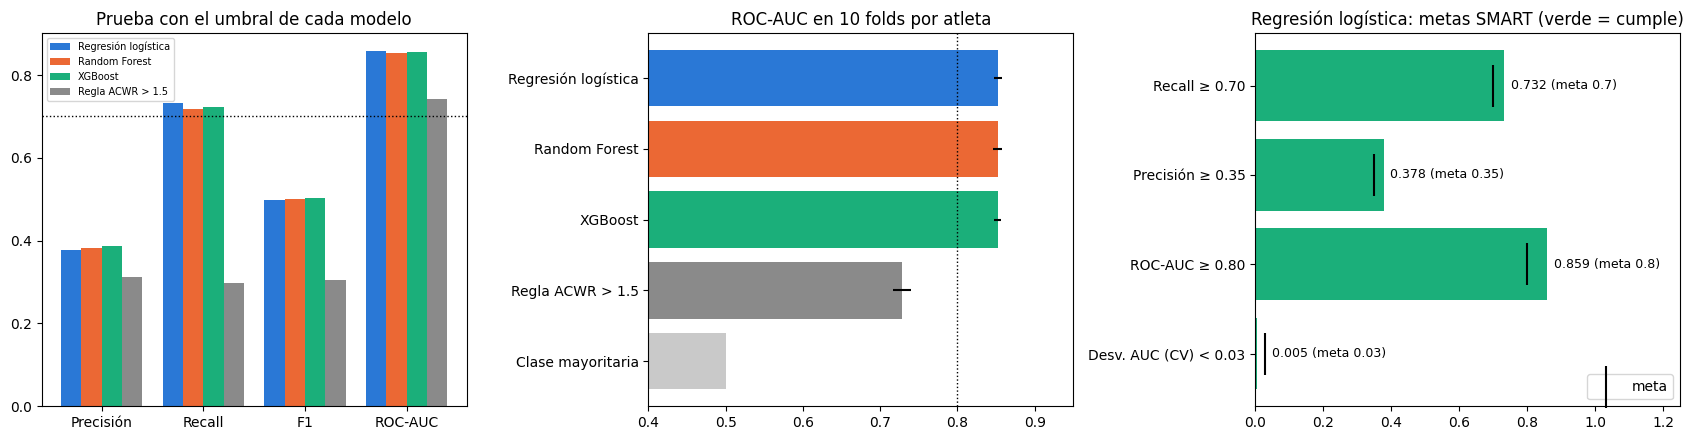

Guardado: resultados/tablero_resumen.png y resultados/resumen.json


In [12]:
# Punto 11. Tablero: panel de resultados y archivo resumen para el tablero web.
import json

orden = ["Regresión logística", "Random Forest", "XGBoost", "Regla ACWR > 1.5", "Clase mayoritaria"]
tabla_final = pd.DataFrame({m: metricas(y_test, prob_test[m], UMBRAL[m]) for m in orden}).T
tabla_final.insert(0, "Umbral", [UMBRAL[m] for m in orden])
tabla_final["CV ROC-AUC (media)"] = [cv[cv["modelo"] == m]["ROC-AUC"].mean() for m in orden]
tabla_final["CV ROC-AUC (desv.)"] = [cv[cv["modelo"] == m]["ROC-AUC"].std() for m in orden]
tabla_final = tabla_final.round(3)
tabla_final.to_csv(RESULTADOS / "tabla_final.csv")
display(tabla_final)

fig, ejes = plt.subplots(1, 3, figsize=(17, 4.5))
# (a) Métricas en prueba por modelo, con su umbral.
x = np.arange(4)
for i, m in enumerate(orden[:4]):
    ejes[0].bar(x + (i - 1.5) * 0.2, tabla_final.loc[m, ["Precisión", "Recall", "F1", "ROC-AUC"]], width=0.2, color=COLOR[m], label=m)
ejes[0].set_xticks(x, ["Precisión", "Recall", "F1", "ROC-AUC"])
ejes[0].axhline(META_RECALL, color="black", ls=":", lw=1)
ejes[0].set_title("Prueba con el umbral de cada modelo")
ejes[0].legend(fontsize=7)
# (b) Validación cruzada: ROC-AUC media ± desviación.
ejes[1].barh(orden[::-1], tabla_final.loc[orden[::-1], "CV ROC-AUC (media)"],
             xerr=tabla_final.loc[orden[::-1], "CV ROC-AUC (desv.)"], color=[COLOR[m] for m in orden[::-1]])
ejes[1].axvline(META_AUC, color="black", ls=":", lw=1)
ejes[1].set_xlim(0.4, 0.95)
ejes[1].set_title("ROC-AUC en 10 folds por atleta")
# (c) Metas SMART del modelo seleccionado.
seleccionado = tabla_final.loc["Regresión logística"]
metas = pd.DataFrame({"valor": [seleccionado["Recall"], seleccionado["Precisión"], seleccionado["ROC-AUC"], seleccionado["CV ROC-AUC (desv.)"]],
                      "meta": [META_RECALL, META_PRECISION, META_AUC, META_DESV_AUC],
                      "cumple": [seleccionado["Recall"] >= META_RECALL, seleccionado["Precisión"] >= META_PRECISION,
                                 seleccionado["ROC-AUC"] >= META_AUC, seleccionado["CV ROC-AUC (desv.)"] < META_DESV_AUC]},
                     index=["Recall ≥ 0.70", "Precisión ≥ 0.35", "ROC-AUC ≥ 0.80", "Desv. AUC (CV) < 0.03"])
ejes[2].barh(metas.index[::-1], metas["valor"][::-1], color=["#1baf7a" if c else "#eb6834" for c in metas["cumple"][::-1]])
ejes[2].scatter(metas["meta"][::-1], metas.index[::-1], marker="|", s=900, color="black", label="meta")
for i, (valor, meta) in enumerate(zip(metas["valor"][::-1], metas["meta"][::-1])):
    ejes[2].text(max(valor, meta) + 0.02, i, f"{valor:.3f} (meta {meta})", va="center", fontsize=9)
ejes[2].set_xlim(0, 1.25)
ejes[2].set_title("Regresión logística: metas SMART (verde = cumple)")
ejes[2].legend(loc="lower right")
plt.tight_layout()
plt.savefig(RESULTADOS / "tablero_resumen.png", dpi=150)
plt.show()

# Resumen para el tablero web.
resumen = {"dataset": DATASET, "umbral": {m: float(UMBRAL[m]) for m in orden},
           "prueba": tabla_final.reset_index(names="modelo").to_dict(orient="records"),
           "prueba_umbral_05": tabla_05.reset_index(names="modelo").to_dict(orient="records"),
           "cv_folds": cv.to_dict(orient="records"),
           "curva_umbral": curvas["Regresión logística"][["Precisión", "Recall", "F1"]].reset_index(names="umbral").to_dict(orient="records"),
           "roc": {m: dict(zip(["fpr", "tpr"], [v[::max(1, len(v) // 150)].round(4).tolist() for v in roc_curve(y_test, prob_test[m])[:2]])) for m in orden[:4]},
           "matriz_05": confusion_matrix(y_test, prob_test["Regresión logística"] >= 0.5).tolist(),
           "matriz_umbral": confusion_matrix(y_test, prob_test["Regresión logística"] >= UMBRAL["Regresión logística"]).tolist(),
           "por_nivel": por_nivel.reset_index(names="nivel").to_dict(orient="records"),
           "significancia": significancia.to_dict(orient="records"), "p_mcnemar": float(P_MCNEMAR),
           "ab": resultado_ab.reset_index().to_dict(orient="records"), "ab_p_ztest": float(P_AB), "ab_p_permutacion": float(P_PERMUTACION),
           "ic_auc": IC_AUC.round(3).tolist(), "versiones": versiones}
(RESULTADOS / "resumen.json").write_text(json.dumps(resumen, ensure_ascii=False, indent=1, default=float))
print("Guardado: resultados/tablero_resumen.png y resultados/resumen.json")

## 12. Justificación técnica e impacto en el negocio

**Decisiones técnicas:** (1) split y validación agrupados por atleta para no inflar resultados; (2) recall como
métrica principal porque el falso negativo es el error caro; (3) umbral elegido solo con entrenamiento; (4) regresión
logística porque ningún modelo complejo la supera de forma significativa y el coach puede entender sus coeficientes.

Se traducen las métricas a lo que vive el coach: por cada **100 atletas** que entrenan una semana, ¿cuántas
sobrecargas se detectan, cuántas se escapan y cuántas alertas tiene que revisar?

In [13]:
# Punto 12. Traducción de métricas a impacto en el negocio (por cada 100 atletas por semana).
# Semanas activas de cada atleta (de su primera a su última sesión) para calcular sesiones por semana.
fechas = pd.to_datetime(datos["date"]).groupby(datos["athlete_id"])
semanas_activas = ((fechas.max() - fechas.min()).dt.days / 7).sum()
sesiones_semana = len(datos) / semanas_activas * 100        # sesiones de 100 atletas en una semana
prevalencia = y_test.mean()
filas = []
for nombre, umbral in [("Regla ACWR > 1.5 (hoy)", None), ("Modelo, umbral 0.5 (Actividad 5)", 0.5),
                       (f"Modelo, umbral {UMBRAL['Regresión logística']:.2f} (propuesto)", UMBRAL["Regresión logística"])]:
    if umbral is None:
        m = metricas(y_test, prob_test["Regla ACWR > 1.5"], UMBRAL_REGLA)
    else:
        m = metricas(y_test, prob_test["Regresión logística"], umbral)
    casos = sesiones_semana * prevalencia
    filas.append({"Escenario": nombre, "Sobrecargas en la semana": casos, "Detectadas": casos * m["Recall"],
                  "Se escapan": casos * (1 - m["Recall"]), "Alertas a revisar": sesiones_semana * m["% alertas"],
                  "Falsas alarmas": sesiones_semana * m["% alertas"] * (1 - m["Precisión"]),
                  "Minutos del coach (2 min/alerta)": sesiones_semana * m["% alertas"] * 2})
impacto = pd.DataFrame(filas).set_index("Escenario").round(0).astype(int)
impacto.to_csv(RESULTADOS / "impacto_negocio.csv")
print(f"100 atletas generan ≈ {sesiones_semana:.0f} sesiones por semana; {prevalencia:.1%} terminan en sobrecarga.")
display(impacto)

100 atletas generan ≈ 312 sesiones por semana; 12.6% terminan en sobrecarga.


,Sobrecargas en la semana,Detectadas,Se escapan,Alertas a revisar,Falsas alarmas,Minutos del coach (2 min/alerta)
Escenario,,,,,,
Regla ACWR > 1.5 (hoy),39,12,28,37,26,75
"Modelo, umbral 0.5 (Actividad 5)",39,10,29,16,6,32
"Modelo, umbral 0.17 (propuesto)",39,29,10,76,47,152


## 13. Conclusiones

- **Exactitud no sirve aquí:** la clase mayoritaria tiene 0.874 de exactitud sin detectar una sola sobrecarga.
- **El modelo ordena bien el riesgo:** ROC-AUC 0.859 en prueba (IC 95 % 0.846 a 0.871) y 0.853 ± 0.005 en 10 folds por
  atleta; generaliza a atletas nuevos.
- **El umbral era el problema, no el modelo:** al bajar el umbral de 0.5 a 0.17 (elegido solo con entrenamiento) el
  recall sube de 0.27 a 0.73 con precisión 0.38. Se cumplen las cuatro metas SMART.
- **Supera claramente a los baselines** (clase mayoritaria y regla ACWR > 1.5) con diferencias significativas
  (t pareada, Wilcoxon con Bonferroni y McNemar). Frente a Random Forest y XGBoost no hay diferencia significativa,
  así que se mantiene la **regresión logística**: más simple, interpretable y rápida.
- **Prueba A/B simulada:** la versión B detecta 70 % de las sobrecargas contra 30 % de la versión A (p < 0.001), a
  cambio de más alertas. El piloto real en Wodify necesita ≈ 268 sobrecargas por grupo.
- **Pendientes:** revisar el recall de los atletas élite (0.62) y mantener la
  revisión del coach sobre cada alerta (el modelo recomienda, el coach decide).